# Assignment 02 - Transforms

This assignment covers robustness testing using data transforms with PyTorch and TorchVision.

## Introduction

As we have seen in class, PyTorch and its related packages provide a powerful means of transforming data in a way that is decoupled from the actual code in our training loop.

The `torch.utils.data.Dataset` and `torch.utils.data.DataLoader` classes provide interfaces for accessing datasets and loading data into our training pipelines. When combined with `torchvision.transforms`, these tools allow us to transform our data without making changes to our core training code. This is incredibly useful for data augmentation, domain generalization, and robustness testing.

For *data augmentation*, transforms can be applied before training to produce useful variation in the dataset, and instill expert knowledge into our models by having experts select which transforms we apply to the training data (e.g., applying rotations to a model which must be rotation invariant), potentially improving model generalization.

Data augmentation is one means to achieve *domain generalization*, i.e., training a model to perform well on domains not encountered during training. Transforms can be applied during training to help us improve our model's ability to generalize to new domains. For example, varying the color of the background randomly ensures the model is not incorrectly sensitive to background color and will not break in a domain with different background colors.

For robustness testing, transforms can be applied after training to assess our model's robustness to controlled perturbations applied to the evaluation data, e.g., blur, color changes, perspective changes, and other variations. We can apply transforms to various degrees using the parameters that PyTorch exposes to adjust the transform. This enables us to extract performance curves for our models which go beyond simply displaying a confusion matrix as the output of model training and show the practical limitations that the model will have when encountering variation from the training data.

This assignment will focus on applying transforms for robustness testing.

## Development and Computing Environment

For this assignment, you may use whichever computing environment you like, whether that be your local computer, Amarel, or another environment. In subsequent assignments, Amarel will be required due to the compute workloads we will need so it is recommended (though not yet required) to begin familiarizing yourself with it and employing it for assignments.

## Directions

In this assignment, we will train a model and assess its robustness using PyTorch. To do this, we will carry out the following steps.

1. **Load Data**: This step will require us to import a torch Dataset and use a torch DataLoader to access it. You may use any dataset you like, as long as it supports image classification (since this assignment is focused on image transforms and assessing accuracy of classification tasks). Datasets built into PyTorch may be used. **0.25 points extra credit will be awarded for implementing a custom Dataset.** Be sure to pick a dataset you have the capacity to train a model on in your development environment. To keep the assignment fair, grading will not be based on the size of the dataset used in any way. Plot a few of the images to ensure you have loaded the data correctly. As always, be sure to divide your dataset into separate training and test sets.

2. **Define the Training Pipeline**: This step will require us to define the class which specifies our neural network architecture, and to define the functions which allow us to train it. We have seen examples of this before, both in class and prior assignments. Be sure to choose an architecture with sufficient capacity to learn the dataset you have chosen in step #1.

3. **Train the Model**: In this step we will use our training functions from step #2 to train a model. Once the model is trained, report baseline test accuracy on untransformed images.

4. **Use Transforms to Test the Model's Robustness Against Blur**: In this step, we will test the model for robustness against an image blur transform. This step will require us to run model inference on the **test** set repeatedly, increasing the amount of image blur with each run. For each image blur level, we will need to save the accuracy, then plot the accuracy against the degree of blur (choose an appropriate metric for the degree of blur), including the baseline accuracy with no blur in the plot. The end result of this step should be a plot of accuracy with respect to degree of blur. Test over a meaningful range of blur severity, aiming to characterize the model's limitations. If performance does not fall to random chance within that range, explain this in your results.

5. **Robustness Test the Model Against a Transform of Your Choice**: In this step, we will test the model for robustness against a transform of our choice (perhaps perspective changes, color changes, or contrast changes). Like Step 4, this step will require us to run inference on the test set with increasing degrees of transformation and plot the resulting accuracy.

## Grading

This assignment is entirely open ended and will not be auto-graded. Each step is worth 20% of the assignment grade. For each step, ensure the following conditions are met to get full credit.

| **Step** | **Criteria for Full Credit** |
|----|----|
| 1. Data Loading | An appropriate image classification dataset is loaded using Dataset and DataLoader, separate training and test sets are established, and example images are visualized. |
| 2. Training Pipeline Definition | A suitable neural network architecture and functional training pipeline are implemented without code errors. |
| 3. Training | The model trains for a sufficient number of epochs, training loss decreases, and baseline test accuracy is reported. |
| 4. Robustness Test - Blur  | A curve of accuracy with respect to degree of blur is produced over a meaningful range of blur severity and is of professional quality. |
| 5. Robustness Test - Other  | A curve of accuracy with respect to degree of transformation over a meaningful range of transformation severity is produced and is of professional quality. |

## Tips

This assignment is intentionally open ended. **No starter code is provided.** The goal of this assignment is to test your ability to put the concepts we have discussed in class into practice.

The steps should be similar, but not necessarily exactly the same, as steps we have discussed in class.

## Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms
from PIL import Image
from tqdm.auto import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print("Using device:", device, "| CPU threads:", torch.get_num_threads())

Using device: cpu | CPU threads: 10


c:\Users\cjpar\assignments\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Step 1 - Load Data

Use the cell below (or make additional cells) to load a torch Dataset and use a torch DataLoader to access it. You may use any dataset you like, as long as it supports image classification (since this assignment is focused on image transforms). Datasets built into PyTorch may be used.

**0.25 points extra credit will be awarded for implementing a custom Dataset.** Be sure to pick a dataset you have the capacity to train a model on in your development environment. To keep the assignment fair, grading will not be based on the size of the dataset used in any way. Plot a few of the images to ensure you have loaded the data correctly.


Loading CIFAR-10 train split (downloads on first run)...
  loaded 50000 images
Loading CIFAR-10 test split (downloads on first run)...
  loaded 10000 images
Train: 50000 images | Test: 10000 images


Checking train loader: 100%|██████████| 391/391 [00:03<00:00, 116.28it/s]


  train: read 50000 images


Checking test loader: 100%|██████████| 40/40 [00:00<00:00, 80.50it/s]


  test: read 10000 images


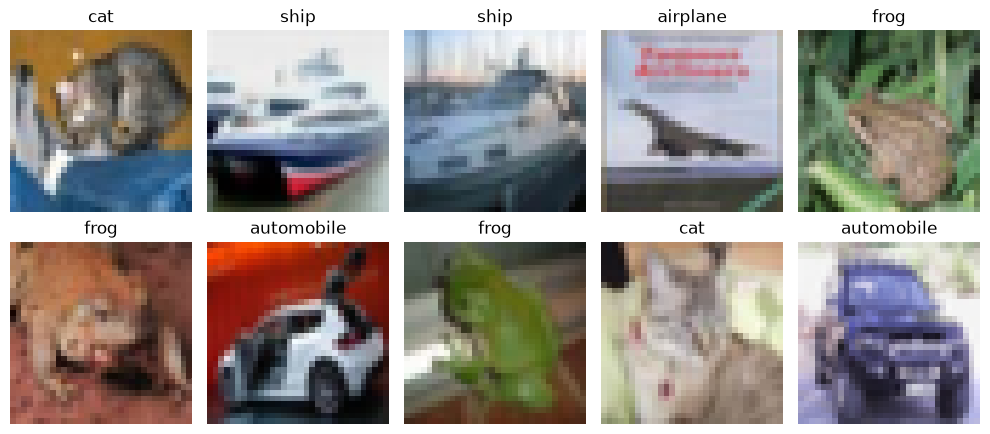

In [4]:
CLASS_NAMES = ["airplane", "automobile", "bird", "cat", "deer",
               "dog", "frog", "horse", "ship", "truck"]

class CustomCIFAR10(Dataset):
    def __init__(self, root="./data", train=True, transform=None):
        split = "train" if train else "test"
        print(f"Loading CIFAR-10 {split} split (downloads on first run)...")
        raw = datasets.CIFAR10(root=root, train=train, download=True)
        self.images = raw.data
        self.labels = np.array(raw.targets)
        self.transform = transform
        print(f"  loaded {len(self.images)} images")

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img = Image.fromarray(self.images[idx])
        label = int(self.labels[idx])
        if self.transform is not None:
            img = self.transform(img)
        return img, label

train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
])
test_transform = transforms.ToTensor()

train_set = CustomCIFAR10(train=True, transform=train_transform)
test_set = CustomCIFAR10(train=False, transform=test_transform)

train_loader = DataLoader(train_set, batch_size=128, shuffle=True, num_workers=0)
test_loader = DataLoader(test_set, batch_size=256, shuffle=False, num_workers=0)

print(f"Train: {len(train_set)} images | Test: {len(test_set)} images")

for name, loader in [("train", train_loader), ("test", test_loader)]:
    n = 0
    for images, labels in tqdm(loader, desc=f"Checking {name} loader"):
        n += images.size(0)
    print(f"  {name}: read {n} images")

fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for ax, i in zip(axes.flat, range(10)):
    img, label = test_set[i]
    ax.imshow(img.permute(1, 2, 0))
    ax.set_title(CLASS_NAMES[label])
    ax.axis("off")
plt.tight_layout()
plt.show()

## Step 2 - Define Training Pipeline

Define a training pipeline like those we have seen in class. Define the class that specifies our neural network architecture and the functions which allow us to train it. We have seen examples of this before, both in class and prior assignments.

Be sure to choose an architecture with sufficient capacity to learn the dataset you have chosen in step #1.

Tip: if you see your architecture is insufficient to learn the dataset you have chosen when you run step 3, you may need to return to step #2 to make your architecture wider or deeper.

In [5]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.Conv2d(16, 16, 3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(64 * 4 * 4, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

def train_one_epoch(model, loader, optimizer, criterion, desc="  batches"):
    model.train()
    total_loss = 0.0
    seen = 0
    pbar = tqdm(loader, desc=desc, leave=False)
    for images, labels in pbar:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        loss = criterion(model(images), labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * images.size(0)
        seen += images.size(0)
        pbar.set_postfix(loss=f"{total_loss / seen:.4f}")
    return total_loss / len(loader.dataset)


@torch.no_grad()
def evaluate(model, loader, desc="  evaluating", show_progress=True):
    model.eval()
    correct = 0
    for images, labels in tqdm(loader, desc=desc, leave=False, disable=not show_progress):
        images, labels = images.to(device), labels.to(device)
        preds = model(images).argmax(dim=1)
        correct += (preds == labels).sum().item()
    return correct / len(loader.dataset)



## Step 3 - Train a Model

Kick off your training run here. Be sure to print or plot the error with respect to the number of epochs so you can see if your model is learning. Once training is complete, report the model's baseline accuracy on the untransformed test set.


Training (epochs):  12%|█▎        | 1/8 [00:27<03:13, 27.70s/it, loss=1.3624]

Epoch  1/8 | train loss: 1.3624


Training (epochs):  25%|██▌       | 2/8 [00:54<02:44, 27.41s/it, loss=0.9733]

Epoch  2/8 | train loss: 0.9733


Training (epochs):  38%|███▊      | 3/8 [01:22<02:16, 27.36s/it, loss=0.8363]

Epoch  3/8 | train loss: 0.8363


... (6 outputs left out)

Training (epochs):  88%|████████▊ | 7/8 [03:14<00:28, 28.24s/it, loss=0.5700]

Epoch  7/8 | train loss: 0.5700


Training (epochs): 100%|██████████| 8/8 [03:42<00:00, 27.86s/it, loss=0.5552]


Epoch  8/8 | train loss: 0.5552


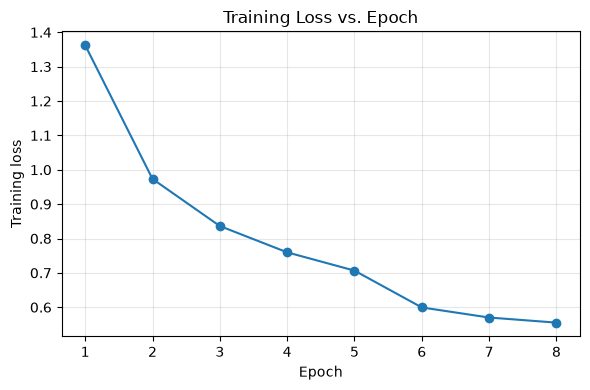

Baseline test accuracy (no transform): 0.8027 (80.27%)


In [7]:
model = SimpleCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.3)

NUM_EPOCHS = 8
train_losses = []

epoch_bar = tqdm(range(NUM_EPOCHS), desc="Training (epochs)")
for epoch in epoch_bar:
    loss = train_one_epoch(model, train_loader, optimizer, criterion,
                           desc=f"  epoch {epoch + 1}/{NUM_EPOCHS} batches")
    scheduler.step()
    train_losses.append(loss)
    epoch_bar.set_postfix(loss=f"{loss:.4f}")
    tqdm.write(f"Epoch {epoch + 1:2d}/{NUM_EPOCHS} | train loss: {loss:.4f}")

plt.figure(figsize=(6, 4))
plt.plot(range(1, NUM_EPOCHS + 1), train_losses, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Training loss")
plt.title("Training Loss vs. Epoch")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

baseline_acc = evaluate(model, test_loader, desc="Baseline test accuracy")
print(f"Baseline test accuracy (no transform): {baseline_acc:.4f} ({baseline_acc * 100:.2f}%)")

## Step 4 - Use Transforms to Robustness Test the Model Against Image Blur

Use the cell below (or add more cells) to write code which repeatedly (e.g., in a for-loop) infers your model on your test set. Each time you do so, apply a blur transform with an increasing amount of blur. Compute and save the average accuracy across the entire test set and then plot the accuracy against the degree of blur (choose an appropriate metric for the degree of blur). Be sure to include the baseline accuracy with no blur applied in the plot. The end result of this step should be a plot of accuracy with respect to degree of blur. Test over a meaningful range of blur severity to characterize the model's limitations. If the model does not fail within that range, explain this in your results.

Include a brief discussion of what your results indicate about the robustness and limitations of your model.


Severity levels:   9%|▉         | 1/11 [00:02<00:21,  2.19s/it]

  level = 0: accuracy = 0.8027


Severity levels:  18%|█▊        | 2/11 [00:08<00:43,  4.84s/it]

  level = 0.25: accuracy = 0.8027


Severity levels:  27%|██▋       | 3/11 [00:17<00:52,  6.58s/it]

  level = 0.5: accuracy = 0.7552


... (12 outputs left out)

Severity levels:  91%|█████████ | 10/11 [01:13<00:06,  6.92s/it]

  level = 5: accuracy = 0.2131


Severity levels: 100%|██████████| 11/11 [01:20<00:00,  7.29s/it]

  level = 6: accuracy = 0.2128


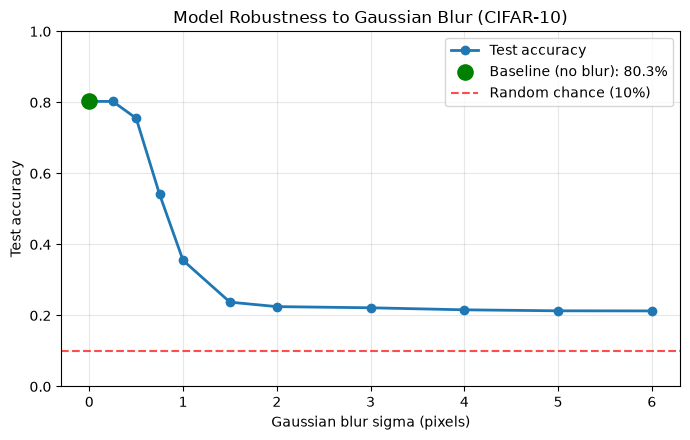

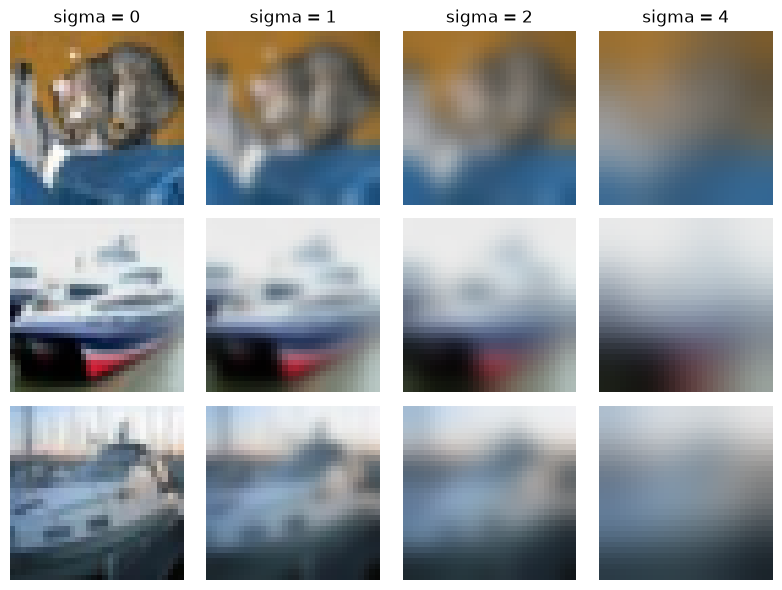

In [8]:
def robustness_sweep(model, make_transform, levels):
    original_transform = test_set.transform
    accuracies = []
    for level in tqdm(levels, desc="Severity levels"):
        test_set.transform = make_transform(level)
        acc = evaluate(model, test_loader, show_progress=False)
        accuracies.append(acc)
        tqdm.write(f"  level = {level}: accuracy = {acc:.4f}")
    test_set.transform = original_transform
    return accuracies

KERNEL_SIZE = 31
blur_sigmas = [0, 0.25, 0.5, 0.75, 1, 1.5, 2, 3, 4, 5, 6]

def make_blur_transform(sigma):
    if sigma == 0:
        return transforms.ToTensor()
    return transforms.Compose([
        transforms.GaussianBlur(kernel_size=KERNEL_SIZE, sigma=sigma),
        transforms.ToTensor(),
    ])

blur_accs = robustness_sweep(model, make_blur_transform, blur_sigmas)


plt.figure(figsize=(7, 4.5))
plt.plot(blur_sigmas, blur_accs, marker="o", linewidth=2, label="Test accuracy")
plt.scatter([0], [blur_accs[0]], s=120, color="green", zorder=3, label=f"Baseline (no blur): {blur_accs[0]:.1%}")
plt.axhline(0.10, color="red", linestyle="--", alpha=0.7, label="Random chance (10%)")
plt.xlabel("Gaussian blur sigma (pixels)")
plt.ylabel("Test accuracy")
plt.title("Model Robustness to Gaussian Blur (CIFAR-10)")
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

show_sigmas = [0, 1, 2, 4]
sample_idx = [0, 1, 2]

fig, axes = plt.subplots(len(sample_idx), len(show_sigmas), figsize=(8, 6))
original_transform = test_set.transform
for col, s in enumerate(show_sigmas):
    test_set.transform = make_blur_transform(s)
    for row, i in enumerate(sample_idx):
        img, label = test_set[i]
        axes[row, col].imshow(img.permute(1, 2, 0))
        axes[row, col].axis("off")
        if row == 0:
            axes[row, col].set_title(f"sigma = {s}")
test_set.transform = original_transform
plt.tight_layout()
plt.show()



### Blur Robustness Discussion

The model's baseline accuracy was 80.3%. Blur at sigma = 0.25 had no measurable effect (80.3%), since a blur
that small barely changes a 32x32 image. Accuracy began to drop at sigma = 0.5 (75.5%) and then fell steeply,
with the largest decline between sigma = 0.5 and sigma = 1 (75.5% to 35.5%). It reached 22.5% by sigma = 2 and
then plateaued, ending at 21.3% at sigma = 6. Accuracy did not fall to the 10% random-chance level within the
tested range. It stabilized at roughly twice chance.

This suggests the model relies heavily on fine, high-frequency detail such as edges and textures, which blur
removes. It was trained only on sharp images, so it has no learned invariance to this kind of degradation.
The plateau above chance likely reflects low-frequency information that survives even heavy blur, such as
dominant color (blue backgrounds for ships and airplanes, green or brown for frogs and deer).

Limitation: in a real setting with out-of-focus or low-quality images, this model's performance would be
unreliable beyond a blur of about sigma = 0.5, where it begins to lose accuracy. By sigma = 1 it has lost
more than half of its baseline accuracy.

## Step 5 - Robustness Test the Model Against a Transform of Your Choice

Repeat Step 4 for a transform of your choice. Create a plot showing how model accuracy changes as the transformation is applied more drastically. Briefly explain why you selected this transform, how you parameterized its severity, and what the results tell you about your model's robustness. Compare the results with your blur experiment. When selecting transformations, and when determining the degree to which they should be applied, consider whether the original image labels remain valid after the transformation is applied. For example, a 6 rotated far enough may become visually indistinguishable from a 9!

As in Step 4, include the untransformed baseline and use the same test samples across all transformation levels.

Severity levels:   9%|▉         | 1/11 [00:02<00:21,  2.19s/it]

  level = 0: accuracy = 0.8027


Severity levels:  18%|█▊        | 2/11 [00:04<00:22,  2.45s/it]

  level = 0.02: accuracy = 0.7914


Severity levels:  27%|██▋       | 3/11 [00:07<00:19,  2.48s/it]

  level = 0.05: accuracy = 0.6573


... (12 outputs left out)

Severity levels:  91%|█████████ | 10/11 [00:24<00:02,  2.52s/it]

  level = 0.75: accuracy = 0.1148


Severity levels: 100%|██████████| 11/11 [00:27<00:00,  2.46s/it]

  level = 1.0: accuracy = 0.1118


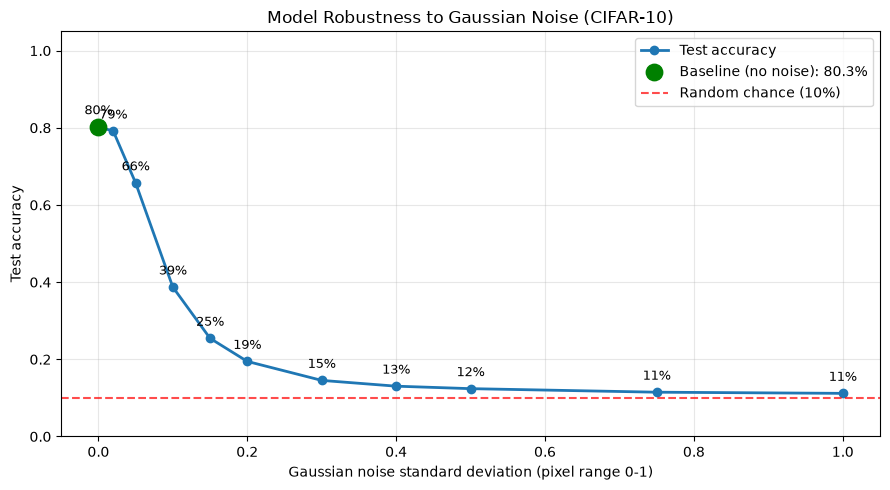

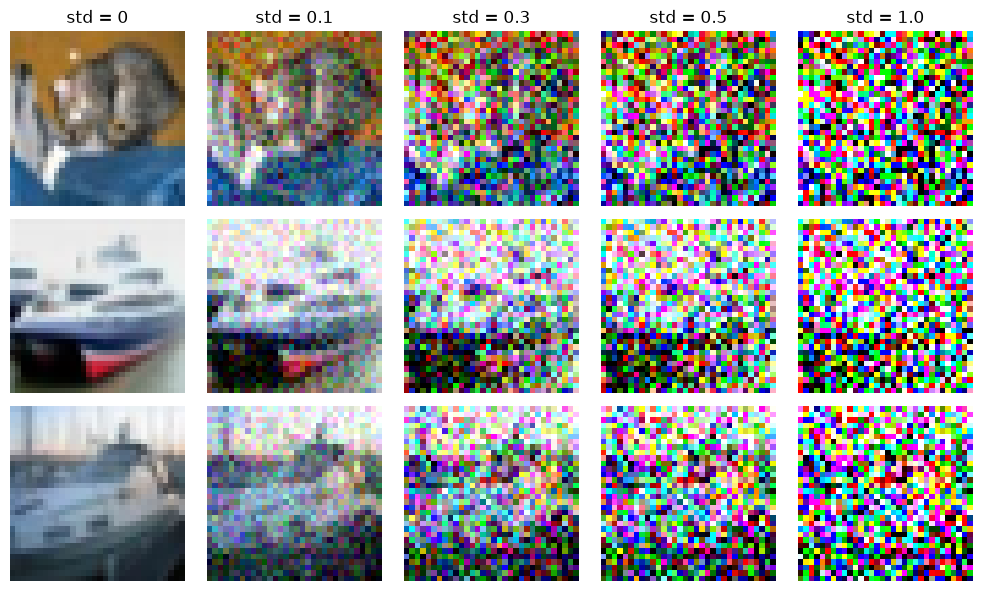

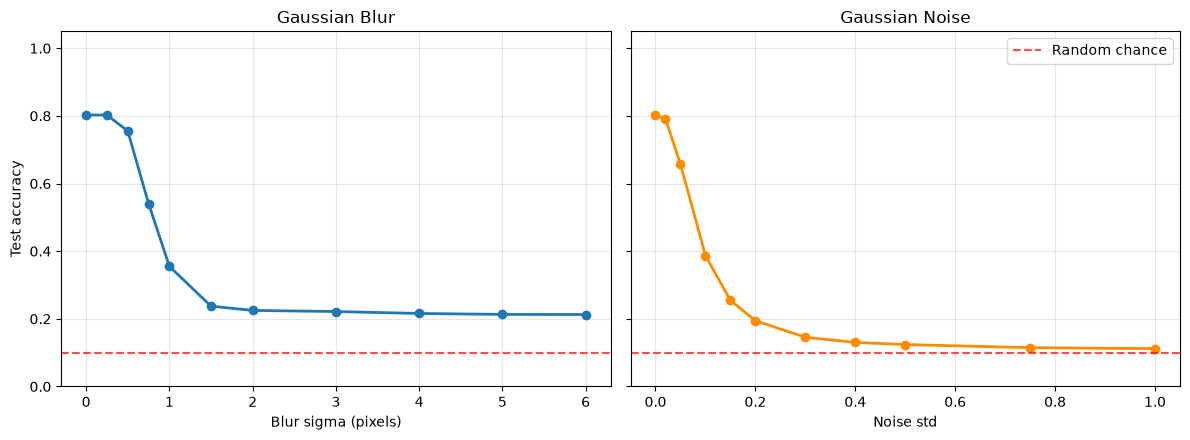

In [9]:
class AddGaussianNoise:
    def __init__(self, std):
        self.std = std

    def __call__(self, tensor):
        return (tensor + torch.randn_like(tensor) * self.std).clamp(0, 1)

noise_stds = [0, 0.02, 0.05, 0.1, 0.15, 0.2, 0.3, 0.4, 0.5, 0.75, 1.0]

def make_noise_transform(std):
    torch.manual_seed(0)
    if std == 0:
        return transforms.ToTensor()
    return transforms.Compose([
        transforms.ToTensor(),
        AddGaussianNoise(std),
    ])

noise_accs = robustness_sweep(model, make_noise_transform, noise_stds)

plt.figure(figsize=(9, 5))
plt.plot(noise_stds, noise_accs, marker="o", linewidth=2, label="Test accuracy")
plt.scatter([0], [noise_accs[0]], s=140, color="green", zorder=3,
            label=f"Baseline (no noise): {noise_accs[0]:.1%}")
plt.axhline(0.10, color="red", linestyle="--", alpha=0.7, label="Random chance (10%)")

for s, a in zip(noise_stds, noise_accs):
    plt.annotate(f"{a:.0%}", (s, a), textcoords="offset points",
                 xytext=(0, 9), ha="center", fontsize=9)

plt.xlabel("Gaussian noise standard deviation (pixel range 0-1)")
plt.ylabel("Test accuracy")
plt.title("Model Robustness to Gaussian Noise (CIFAR-10)")
plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

show_stds = [0, 0.1, 0.3, 0.5, 1.0]
sample_idx = [0, 1, 2]

fig, axes = plt.subplots(len(sample_idx), len(show_stds), figsize=(10, 6))
original_transform = test_set.transform
for col, s in enumerate(show_stds):
    test_set.transform = make_noise_transform(s)
    for row, i in enumerate(sample_idx):
        img, label = test_set[i]
        axes[row, col].imshow(img.permute(1, 2, 0))
        axes[row, col].axis("off")
        if row == 0:
            axes[row, col].set_title(f"std = {s}")
test_set.transform = original_transform
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)

axes[0].plot(blur_sigmas, blur_accs, marker="o", linewidth=2)
axes[0].axhline(0.10, color="red", linestyle="--", alpha=0.7)
axes[0].set_xlabel("Blur sigma (pixels)")
axes[0].set_ylabel("Test accuracy")
axes[0].set_title("Gaussian Blur")

axes[1].plot(noise_stds, noise_accs, marker="o", linewidth=2, color="darkorange")
axes[1].axhline(0.10, color="red", linestyle="--", alpha=0.7, label="Random chance")
axes[1].set_xlabel("Noise std")
axes[1].set_title("Gaussian Noise")
axes[1].legend()

for ax in axes:
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()



### Noise Robustness Discussion

**Why this transform:** I chose Gaussian noise because it preserves the image's label at moderate levels and
contrasts with blur: blur removes high-frequency detail, while noise adds it. Sensor noise and low-light
conditions make it a realistic perturbation.

**Severity parameterization:** Noise standard deviation, applied to pixel values in the range 0-1, with
results clamped back to [0, 1]. A fixed random seed and the same 10,000 test images were used at every level.
Labels remain valid for moderate noise, but by std ≈ 0.3 the images in the example grid are hard even for a
human to recognize, so accuracy beyond that point partly reflects a perturbation that has erased the content
rather than a pure failure of the model.

**Results:** Baseline accuracy was 80.3%. Accuracy was nearly unchanged at std = 0.02 (79.1%), then dropped
sharply from std = 0.05 (65.7%). The steepest decline occurred between std = 0.05 and std = 0.15, where
accuracy fell from 65.7% to 25.5%. It was below 20% by std = 0.2 and continued to decline slowly toward
chance. At std = 1.0, accuracy was 11.2%, close to the 10% random-chance level, so the model was effectively
guessing at the high end of the tested range.

**Comparison with blur:** Both perturbations cut accuracy roughly in half at mild severity: noise at std ≈ 0.1
(38.7%) and blur at sigma ≈ 1 (35.5%). The two parameters have different units, so the more informative
difference is how the curves end. Blur plateaued at about 21%, well above chance, because it destroys fine
detail but preserves the coarse color layout. Noise fell to about 11%, near chance, because it corrupts every
pixel independently and eventually overwhelms the color information too. The model was also very brittle to
faint noise: it lost about 15 points at std = 0.05, a level that is barely visible to a person. Both
experiments show the model was trained only on clean images and has no learned invariance to either kind of
degradation. Training with noise or blur augmentation would be a natural way to improve robustness.